In [ ]:
import os
import sys
from pathlib import Path

if "google.colab" in sys.modules and not Path("src").exists():
    print("Запуск у Google Colab — переконайтесь, що папка 'src/' завантажена у робочу директорію.")

import src
import keras
import tensorflow as tf
import pandas as pd

from src.config import SEED, ensure_directories, set_global_seed

ensure_directories()
set_global_seed(SEED)
accel_info = f"TF devices: {tf.config.list_physical_devices()}"
if keras.backend.backend() == "torch":
    import torch
    mps_ok = torch.backends.mps.is_available()
    accel_info = f"Apple Metal GPU (MPS): {'ACTIVE' if mps_ok else 'CPU'} (torch {torch.__version__})"
print(f"Keras: {keras.__version__} (backend={keras.backend.backend()}) | TensorFlow: {tf.__version__}")
print(f"Апаратне прискорення: {accel_info}")


Keras: 3.15.1 (backend=torch) | TensorFlow: 2.21.0
Апаратне прискорення: Apple Metal GPU (MPS): ACTIVE (torch 2.15.0)


In [2]:
from src.config import MODEL_SPECS, MODELS_DIR
from src.models_factory import assemble_end_to_end_model
from src.trainer import (
    extract_or_load_features,
    finalize_and_save_model,
    predict_external_images,
    release_memory,
    train_head_experiment,
)
from src.visualization import (
    plot_confusion_matrix,
    plot_external_predictions_grid,
    plot_training_curves,
)

spec = MODEL_SPECS["inception_v3"]
print(f"Модель: {spec.display_name} | Розмір входу: {spec.image_size} | Препроцесинг: {spec.preprocess_description}")


Модель: InceptionV3 | Розмір входу: (299, 299) | Препроцесинг: TF-style (pixels scaled to [-1, 1])


In [ ]:
features, extract_sec = extract_or_load_features("inception_v3")
print(f"Розмірність вектора ознак після GlobalAveragePooling2D: {features['train'][0].shape[1]}")
print(f"Час екстракції на повному датасеті: {extract_sec:.1f} с")

Found 19997 files belonging to 2 classes.
Found 2498 files belonging to 2 classes.
Found 2502 files belonging to 2 classes.
[trainer] Extracting frozen features for 'train' split ...
[trainer] Extracting frozen features for 'val' split ...
[trainer] Extracting frozen features for 'test' split ...
Розмірність вектора ознак після GlobalAveragePooling2D: 2048
Час екстракції на повному датасеті: 667.5 с


MPS GPU [test]: 100%|##########| 79/79 [01:06<00:00,  1.18it/s]


Best Epoch: 4 | Best Val Acc: 99.40%
Test Acc (features): 99.32% | ROC-AUC: 0.99906


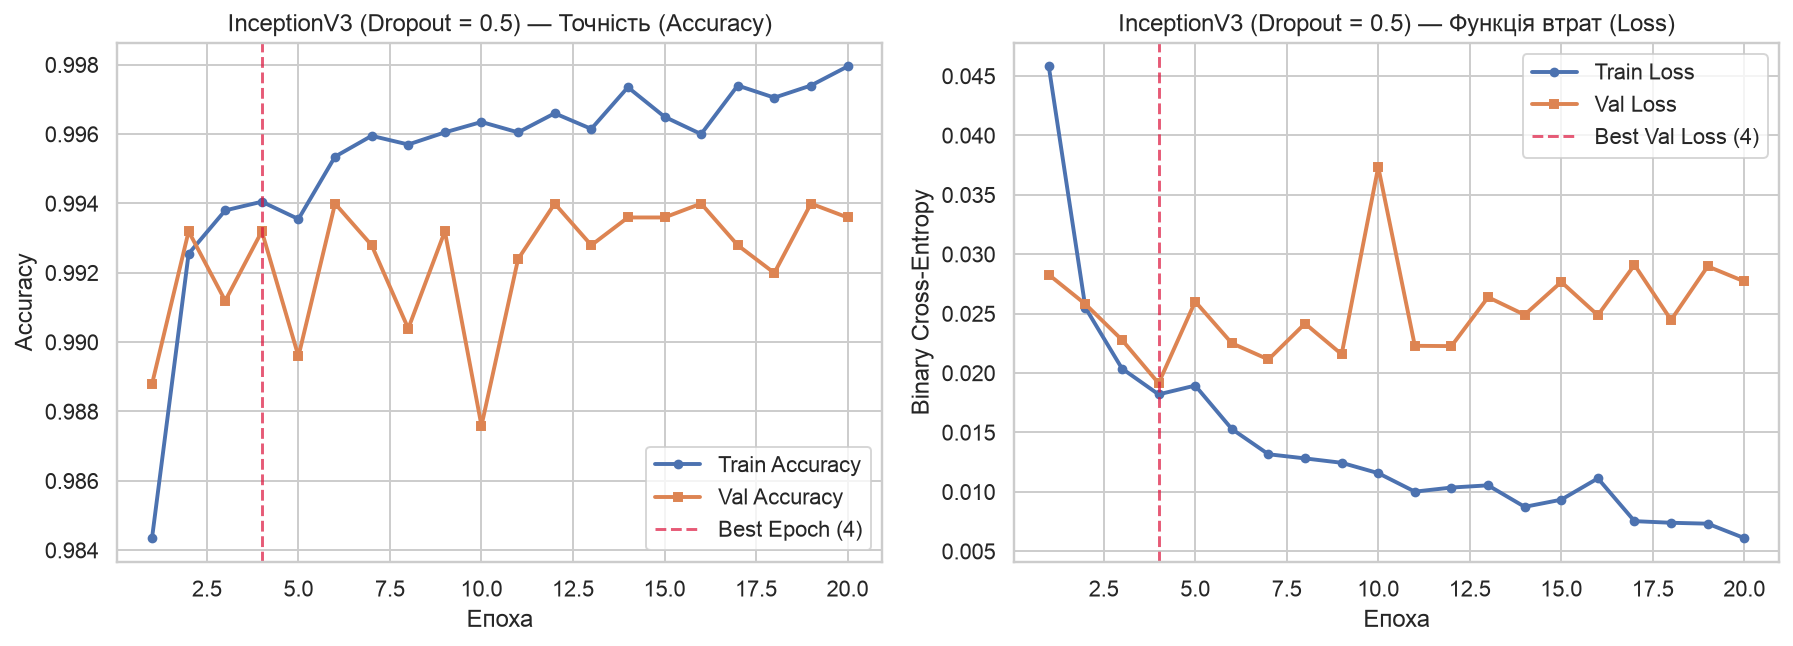

In [ ]:
release_memory()
trained_head, exp_record = train_head_experiment(
    model_key="inception_v3",
    features=features,
    dropout_rate=0.5,
    epochs=20,
    restore_best_weights=True,
    experiment_name="inception_v3_do_0_5",
)

print(f"Best Epoch: {exp_record['best_epoch']} | Best Val Acc: {exp_record['best_val_accuracy']*100:.2f}%")
print(f"Test Acc (features): {exp_record['test_metrics']['accuracy']*100:.2f}% | ROC-AUC: {exp_record['test_metrics']['roc_auc']:.5f}")
plot_training_curves(exp_record, save_name="03_inception_v3_curves.png")

Model: "inception_v3_transfer_learning"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_rgb (InputLayer)          │ (None, 299, 299, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ inception_v3_rescale            │ (None, 299, 299, 3)    │             0 │
│ (Rescaling)                     │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ inception_v3 (Functional)       │ (None, 8, 8, 2048)     │    21,802,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_avg_pool                 │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼─

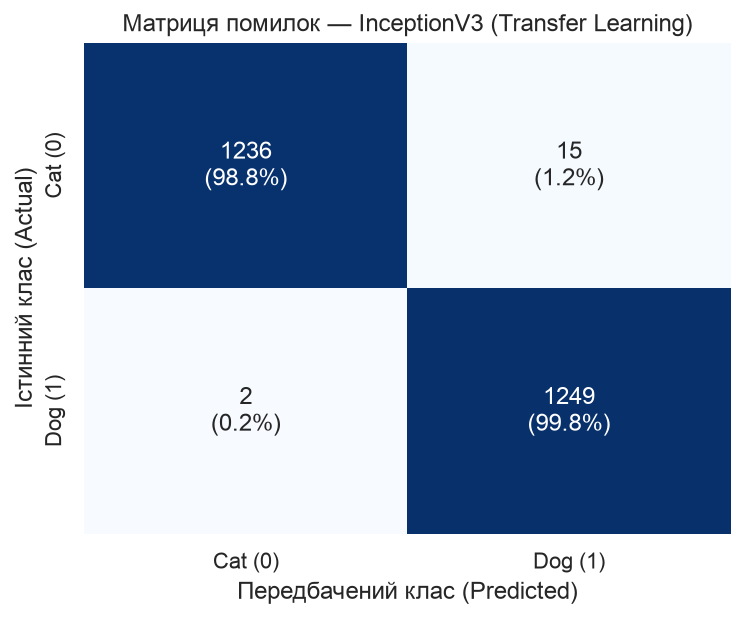

In [5]:
preview_model = assemble_end_to_end_model("inception_v3", trained_head, dropout_rate=0.5)
preview_model.summary()
del preview_model

final_summary = finalize_and_save_model(
    model_key="inception_v3",
    trained_head=trained_head,
    experiment_record=exp_record,
    extraction_seconds=extract_sec,
)

plot_confusion_matrix(
    final_summary["test_metrics"]["confusion_matrix"],
    model_title="InceptionV3 (Transfer Learning)",
    save_name="03_inception_v3_confusion_matrix.png",
)


,filename,rel_path,true_class,pred_class,dog_probability,confidence,correct
0,ext_cat_01_tabby.jpg,cats/ext_cat_01_tabby.jpg,cats,cats,0.0000,1.0000,True
1,ext_cat_02_orange.jpg,cats/ext_cat_02_orange.jpg,cats,cats,0.0000,1.0000,True
2,ext_cat_03_white_cat.jpg,cats/ext_cat_03_white_cat.jpg,cats,cats,0.0001,0.9999,True
3,ext_cat_04_kitten.jpg,cats/ext_cat_04_kitten.jpg,cats,cats,0.0000,1.0000,True
4,ext_cat_05_portrait.jpg,cats/ext_cat_05_portrait.jpg,cats,cats,0.0000,1.0000,True
5,ext_dog_01_golden_retriever.jpg,dogs/ext_dog_01_golden_retriever.jpg,dogs,dogs,1.0000,1.0000,True
6,ext_dog_02_samoyed.jpg,dogs/ext_dog_02_samoyed.jpg,dogs,dogs,0.9907,0.9907,True
7,ext_dog_03_beagle.jpg,dogs/ext_dog_03_beagle.jpg,dogs,dogs,1.0000,1.0000,True
8,ext_dog_04_german_shepherd.jpg,dogs/ext_dog_04_german_shepherd.jpg,dogs,dogs,1.0000,1.0000,True
9,ext_dog_05_pug.jpg,dogs/ext_dog_05_pug.jpg,dogs,dogs,0.9983,0.9983,True


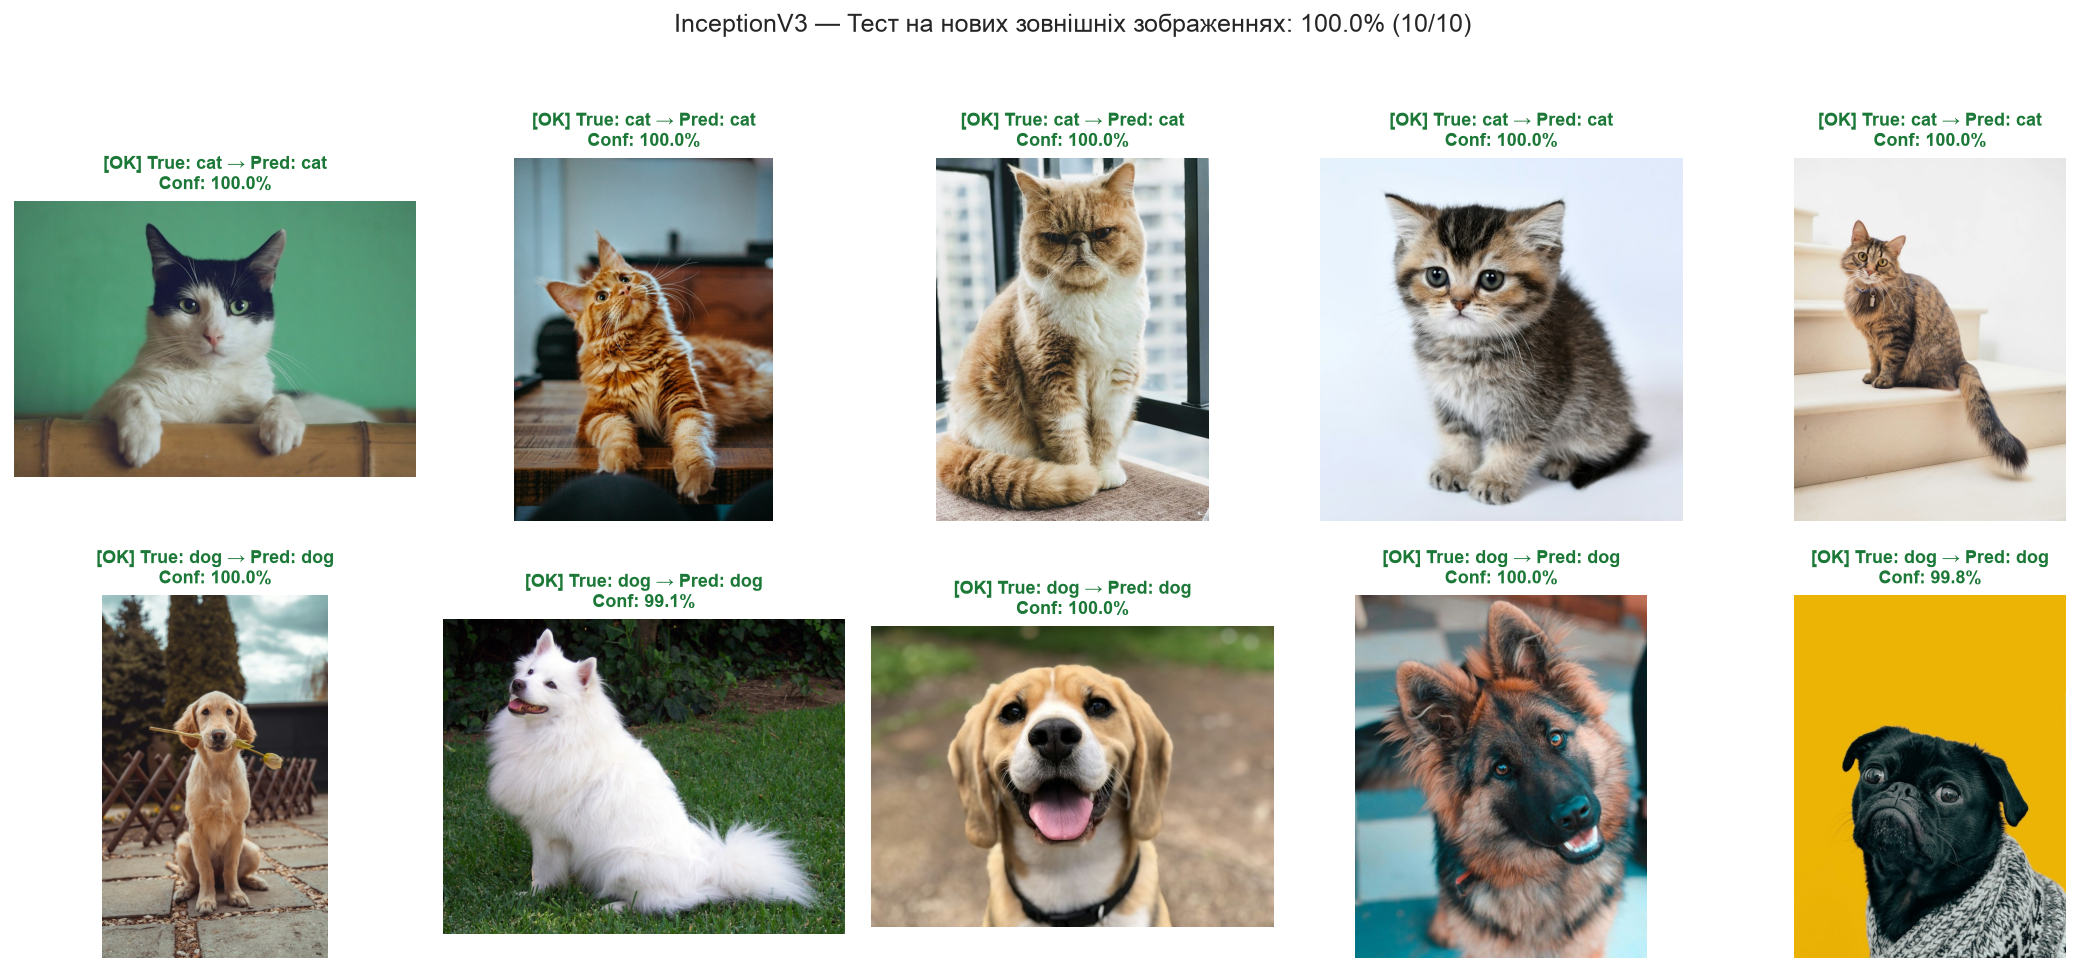

In [6]:
df_ext = predict_external_images(MODELS_DIR / spec.save_filename)
display(df_ext)
plot_external_predictions_grid(
    df_ext,
    model_title="InceptionV3",
    save_name="03_inception_v3_external_test.png",
)
